# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
NX_, NY_, NZ_ = 512, 512, 300
n_voxels = NX_ * NY_ * NZ_
scan_mb = n_voxels * 2 / 1024**2 

# TODO 2
extent_mm = (NX_ * 0.5, NY_ * 0.5, NZ_ * 1.0)   # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
rays_per_frame = NX_ * NZ_                 
samples_per_ray = NY_                     
samples_per_frame = rays_per_frame * samples_per_ray
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

1. Distorted shapes in the coronal and sagittal views. In those two views one screen axis is *z*, where the voxels are twice as thick (1.0 mm) as in *x* and *y* (0.5 mm). If the software draws every voxel as a square pixel, the head is squashed to half its real height. A round tumour looks like a flat ellipse and the anatomy looks wrong. The fix is to display with the correct voxel aspect ratio (here aspect = dz/dx; for the phantom's 4×3×3 mm voxels that is ASPECT = 4/3).

2. Wrong measurements. The software would measure distances, sizes and volumes in voxel units instead of millimetres. A distance read along *z* would be only half its real value, and a volume computed as voxels × (0.5 mm)³ instead of voxels × 0.25 mm³ would be wrong by a factor of 2. For a tumour-board that decides on surgical margins and treatment response, this is a clinical error, not just a cosmetic one. Related to both: the *z* resolution is coarser, so reformatted views show more stair-stepping and blur along *z* than along *x* and *y*.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 component(s); lesion = 431 voxels; centroid (z, y, x) = (28, 40, 41)


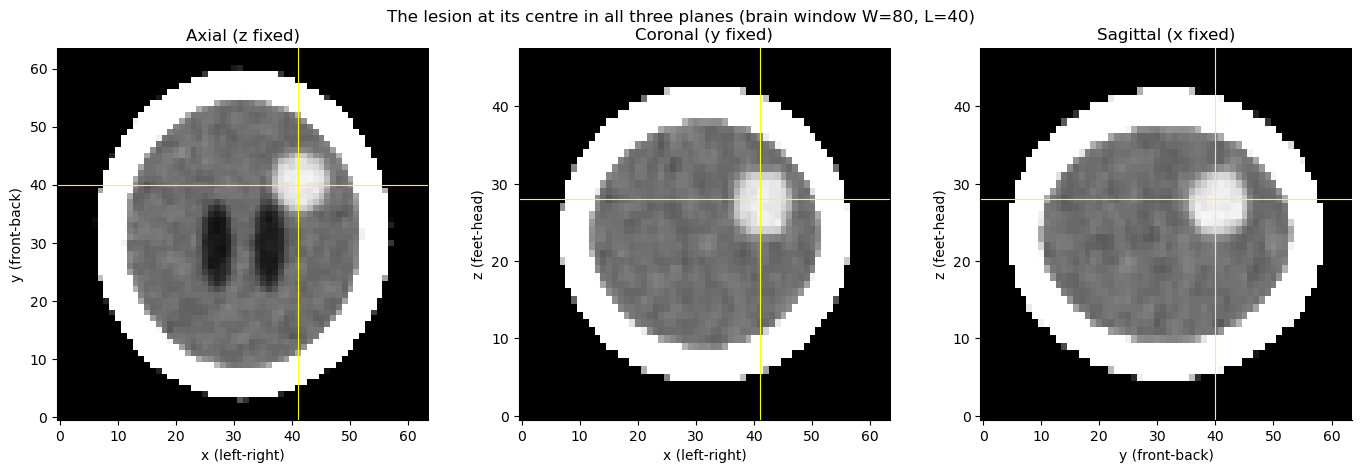

Distance from true tumour centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2
comp, n_comp = ndimage.label(candidates)
sizes = np.bincount(comp.ravel())[1:]                     
lesion = comp == (np.argmax(sizes) + 1)             
cz, cy, cx = [int(round(c)) for c in ndimage.center_of_mass(lesion)]
print(f"{n_comp} component(s); lesion = {lesion.sum()} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [
    ("Axial (z fixed)",    vol[cz, :, :], None,   cx, cy, "x (left-right)",  "y (front-back)"),
    ("Coronal (y fixed)",  vol[:, cy, :], ASPECT, cx, cz, "x (left-right)",  "z (feet-head)"),
    ("Sagittal (x fixed)", vol[:, :, cx], ASPECT, cy, cz, "y (front-back)",  "z (feet-head)"),
]
for ax, (title, sl, asp, hx, hy, xl, yl) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp or 1, vmin=0, vmax=1)
    ax.axvline(hx, color="yellow", lw=0.8); ax.axhline(hy, color="yellow", lw=0.8)     
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
fig.suptitle("The lesion at its centre in all three planes (brain window W=80, L=40)")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tz, ty, tx = ndimage.center_of_mass(labels == 5)
err_mm = np.sqrt(((cz - tz) * SPACING[0]) ** 2 + ((cy - ty) * SPACING[1]) ** 2 + ((cx - tx) * SPACING[2]) ** 2)
print(f"Distance from true tumour centroid: {err_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

What the erosion does. The HU range 55–90 is not unique to the tumour. Where the brain (about 40 HU) meets the skull (about 700 HU), a voxel that is partly brain and partly bone gets a blended value (the partial-volume effect), and some of these boundary voxels land by chance inside 55–90 HU. They then look exactly like tumour tissue. This is the overlapping-intensity-ranges challenge from Slide 28: a single threshold or transfer function cannot separate materials whose HU ranges overlap, and boundary blending creates fake "intermediate" materials.

In this volume, the 55–90 HU mask without any erosion contains 1,723 voxels in 720 separate components, but only 431 of them belong to the tumour. The other 1,292 are mostly such shell voxels under the skull. After 3 erosion iterations only the tumour remains (431 voxels in one component). The erosion works by adding *spatial* information (distance from the bone) that the intensity alone does not carry. The price is that it would also erode a real lesion lying within 3 voxels of the skull, so this step suits this phantom but must be used carefully on real lesions near bone.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_HU,voxels,volume_mL,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


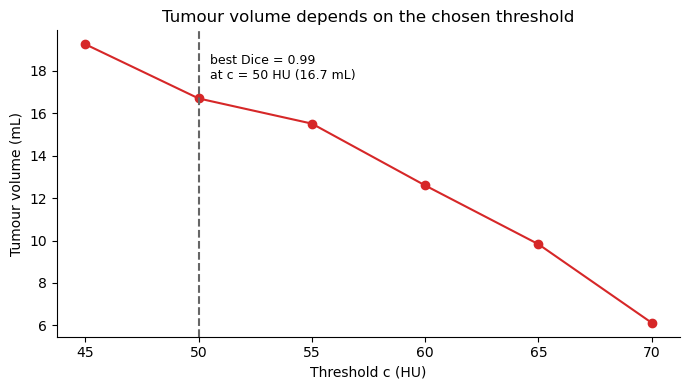

Report to the surgeon: 6.1 - 19.3 mL (best single estimate 16.7 mL at c = 50 HU; true volume 16.7 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    comp, _ = ndimage.label(vol > c)
    grown = comp == comp[cz, cy, cx]                         
    n_vox = int(grown.sum())
    dice = 2 * (grown & truth).sum() / (grown.sum() + truth.sum())  
    rows.append({"threshold_HU": c, "voxels": n_vox, "volume_mL": n_vox * VOXEL_MM3 / 1000, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_HU, table.volume_mL, "o-", color="tab:red")
best = table.loc[table.dice.idxmax()]
ax.axvline(best.threshold_HU, color="0.4", ls="--")
ax.annotate(f"best Dice = {best.dice:.2f}\nat c = {best.threshold_HU:.0f} HU ({best.volume_mL:.1f} mL)",
            (best.threshold_HU, best.volume_mL), xytext=(8, 14), textcoords="offset points", fontsize=9)
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Tumour volume depends on the chosen threshold")
plt.tight_layout(); plt.show()

# TODO 4
print(f"Report to the surgeon: {table.volume_mL.min():.1f} - {table.volume_mL.max():.1f} mL "
      f"(best single estimate {best.volume_mL:.1f} mL at c = {best.threshold_HU:.0f} HU; "
      f"true volume {truth.sum() * VOXEL_MM3 / 1000:.1f} mL)")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

Choosing c without ground truth. I would not trust a single arbitrary number. A defensible choice is the half-way (full-width-half-maximum) value between the HU of the tumour interior and the HU of the surrounding brain. For example, with the tumour centre around 66 HU and the normal brain around 40 HU, that gives about 50–55 HU. The tumour boundary is where the voxel value is half-way between the two materials. In this notebook, c = 50 HU also gave the best Dice (0.99) and a volume of 16.7 mL, which matches the true volume, so the evaluation supports that choice. I would justify it to the board by measuring the two reference intensities from regions I sample inside the tumour and in the surrounding brain, and I would confirm the contour on the slices.

Showing the uncertainty. The volume changes a lot with the threshold: about 19.3 mL at 45 HU down to about 6.1 mL at 70 HU. For a defensible range I would report the neighbourhood of the best threshold (for example 15.5–19.3 mL for c = 45–55 HU) rather than one number. To visualize this, I would:
- show the volume-versus-threshold curve (as in Task 3) with the chosen c marked and a shaded band for the reported range;
- overlay several threshold contours (for example 45, 50 and 55 HU) on the axial, coronal and sagittal slices, so the surgeon can see where the boundary is stable and where it moves;
- report the volume as "about 16.7 mL (range 15.5–19.3 mL)" and never as 16.704 mL, because the extra digits suggest a precision that does not exist.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

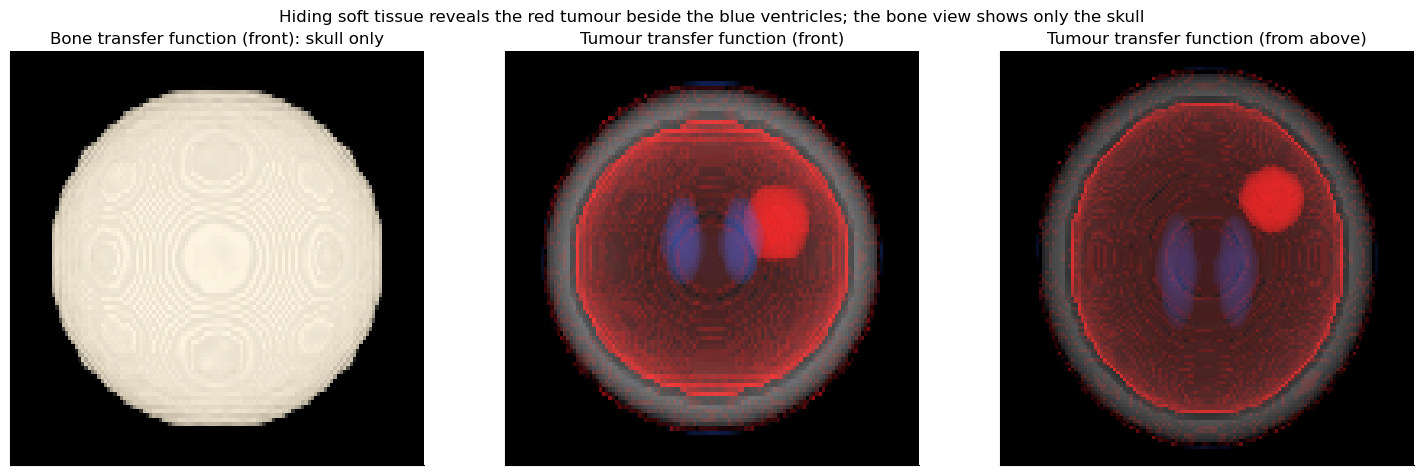

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0),       0.0),
    (3,     (0, 0, 0),       0.0),
    (5,     (0.2, 0.4, 1.0), 0.02),     
    (20,    (0.2, 0.4, 1.0), 0.02),
    (24,    (0, 0, 0),       0.0),     
    (45,    (0, 0, 0),       0.0),
    (50,    (1.0, 0.1, 0.1), 0.10),     
    (80,    (1.0, 0.1, 0.1), 0.10),
    (90,    (0, 0, 0),       0.0),
    (300,   (0, 0, 0),       0.0),
    (400,   (1, 1, 1),       0.01),    
    (1500,  (1, 1, 1),       0.01),
])


fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C, A = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT)
axes[0].set_title("Bone transfer function (front): skull only")

C, A = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT)
axes[1].set_title("Tumour transfer function (front)")

C, A = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C, 0, 1), origin="lower")
axes[2].set_title("Tumour transfer function (from above)")

for ax in axes:
    ax.set_facecolor("black")
    ax.set_xticks([]); ax.set_yticks([])

# TODO 4: suptitle
fig.suptitle("Hiding soft tissue reveals the red tumour beside the blue ventricles; the bone view shows only the skull", fontsize=12)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

Which challenge. The faint red rim is caused by the partial-volume effect together with overlapping intensity ranges (Slide 28). At the brain–skull boundary, voxels are a blend of brain and bone. Some of them get an HU value in the tumour range (about 50–80 HU), so the transfer function colours them red even though they are not tumour. Because the rim is a thin shell seen along the whole circumference, it is visible in the render as a red ring just inside the skull.

Technique that removes it. Segmentation or masking before rendering (Slides 31–32): first segment the tumour (for example the thresholded and connected-component region from Task 3, or a clip or mask that excludes the shell under the skull) and render only that region, or erode or clip away the shell voxels before rendering. Another option is to use a 2-D transfer function that includes the *gradient magnitude* (a boundary measure) in addition to the intensity, which can suppress boundary voxels.

Why the transfer function alone cannot. A 1-D transfer function maps each voxel's intensity to a colour and an opacity, and it sees only that single value. A real tumour voxel at 65 HU and a blended boundary voxel at 65 HU are identical to it, so it must treat them the same way. Telling them apart requires information that the intensity does not contain, namely the voxel's spatial context (where it is, what it touches). That is exactly what segmentation, masking or gradient-based classification add.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion is a roughly round, soft-tissue mass in the upper-right region of the brain (right on the image) near the skull, beside the paired ventricles, and its volume is about 16.7 mL, with a plausible range of about 15.5–19.3 mL depending on the threshold (45–55 HU); thresholds of 60 HU or higher begin to cut real tumour away, shrinking the estimate to 12.6 mL and lower. I recommend opening the meeting with the three-plane MPR with a segmentation overlay, because slicing exposes the internal structure that the 3-D render hides, and the segmentation is what makes a measurement (volume, with its uncertainty) possible at all. The 3-D volume rendering comes second, as a way to show the tumour's relation to the ventricles after the board has seen the numbers. One limitation of the 3-D render to keep in mind is that its colours and opacities come from a transfer function, and overlapping intensity ranges and partial-volume voxels can create spurious structures, such as the faint red rim under the skull, so the render must never be used for measurement and must always be checked against the slices.